# 11 - Análise exploratória dos dados interim (v2)

**Objetivo:** caracterizar as descrições dos itens fiscais, sua frequência, os códigos NCM e algumas variáveis fiscais antes dos experimentos de modelagem.

Esta versão usa exclusivamente os arquivos mensais Parquet em `data/interim/items-notas-fiscais/`. Cada linha com descrição do produto/serviço preenchida é tratada como item; linhas de metadados da nota, sem descrição de item, ficam fora das análises de itens. Os arquivos originais permanecem inalterados e este notebook não grava arquivos.


In [5]:
from __future__ import annotations

import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq

pd.options.display.max_columns = 80
pd.options.display.max_colwidth = 120
plt.style.use("default")


## Configuração

A pasta de dados é relativa à raiz do repositório. Execute o notebook com a raiz do projeto como diretório de trabalho. `MONTHS` pode limitar a análise a competências específicas; `None` inclui todos os arquivos mensais disponíveis.


In [6]:
INTERIM_DIR = Path("data/interim/2025")
if not INTERIM_DIR.is_dir() and Path.cwd().name == "notebooks":
    INTERIM_DIR = Path("..") / INTERIM_DIR
MONTHS = None  # Ex.: ("2025-01", "2025-02"); None usa todos os meses disponíveis.
TOP_N = 20

DESCRIPTION_TERMS = ("DESCRICAO", "PRODUTO", "SERVICO")
NCM_CODE_TERMS = ("CODIGO", "NCM", "SH")
NCM_TYPE_TERMS = ("NCM", "TIPO", "PRODUTO")
FISCAL_COLUMN_TERMS = {
    "serie": ("SERIE",),
    "natureza_operacao": ("NATUREZA", "OPERACAO"),
    "razao_social_emitente": ("RAZAO", "SOCIAL", "EMITENTE"),
    "consumidor_final": ("CONSUMIDOR", "FINAL"),
    "presenca_comprador": ("PRESENCA", "COMPRADOR"),
}
FISCAL_COLUMN_LABELS = {
    "serie": "Série",
    "natureza_operacao": "Natureza da operação",
    "razao_social_emitente": "Razão social emitente",
    "consumidor_final": "Consumidor final",
    "presenca_comprador": "Presença do comprador",
}


In [7]:
def normalize_column_name(name: object) -> str:
    """Normalize a column name for accent-insensitive matching."""
    text = unicodedata.normalize("NFKD", str(name))
    return "".join(char for char in text if not unicodedata.combining(char)).upper()


def find_column(columns: pd.Index, required_terms: tuple[str, ...]) -> str:
    """Find the first column whose normalized name contains all required terms."""
    terms = tuple(normalize_column_name(term) for term in required_terms)
    for column in columns:
        normalized = normalize_column_name(column)
        if all(term in normalized for term in terms):
            return str(column)
    raise KeyError(f"Nenhuma coluna encontrada para os termos {required_terms}.")


def optional_column(columns: pd.Index, required_terms: tuple[str, ...]) -> str | None:
    """Find a matching column, returning None when it is absent."""
    try:
        return find_column(columns, required_terms)
    except KeyError:
        return None


def clean_categorical_series(series: pd.Series) -> pd.Series:
    """Trim categorical values and convert empty strings to missing values."""
    return series.astype("string").str.strip().replace("", pd.NA)


def noise_reasons(text: object) -> list[str]:
    """Return simple heuristic flags for a potentially noisy description."""
    value = "" if pd.isna(text) else str(text).strip()
    compact = re.sub(r"\s+", "", value)
    reasons = []
    if not value:
        reasons.append("vazia")
    if 0 < len(value) <= 3:
        reasons.append("muito_curta")
    if compact.isdigit():
        reasons.append("apenas_numeros")
    if sum(char.isdigit() for char in value) >= 5:
        reasons.append("muitos_digitos")
    if any(marker in value.lower() for marker in ["\ufffd", "??", "***", "xxx", "diversos"]):
        reasons.append("marcador_ruido")
    if value and sum(not char.isalnum() and not char.isspace() for char in value) / len(value) > 0.25:
        reasons.append("muitos_simbolos")
    return reasons


def summarize_categorical_column(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    """Summarize missingness, cardinality and the most common value."""
    values = clean_categorical_series(frame[column])
    return pd.DataFrame([{
        "coluna": FISCAL_COLUMN_LABELS[column],
        "total_itens": len(values),
        "valores_ausentes": int(values.isna().sum()),
        "proporcao_ausente": values.isna().mean(),
        "valores_distintos": int(values.nunique(dropna=True)),
        "valor_mais_frequente": values.mode(dropna=True).iat[0] if values.notna().any() else pd.NA,
    }])


def top_categorical_values(frame: pd.DataFrame, column: str, limit: int = 15) -> pd.DataFrame:
    """Return the most common values in a categorical column."""
    values = clean_categorical_series(frame[column]).fillna("<ausente>")
    return (
        values.value_counts(dropna=False).head(limit).rename_axis("valor")
        .reset_index(name="total_itens")
        .assign(coluna=FISCAL_COLUMN_LABELS[column], proporcao=lambda data: data["total_itens"] / len(frame))
        [["coluna", "valor", "total_itens", "proporcao"]]
    )


def load_interim_items(interim_dir: Path, months: tuple[str, ...] | None = None) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Load monthly interim Parquets and return all rows plus rows with item descriptions."""
    parquet_files = sorted(interim_dir.glob("*.parquet"))
    if months is not None:
        parquet_files = [path for path in parquet_files if path.stem in months]
    if not parquet_files:
        raise FileNotFoundError(f"Nenhum Parquet mensal encontrado em {interim_dir} para MONTHS={months}.")

    monthly_frames = []
    for parquet_file in parquet_files:
        schema_columns = pd.Index(pq.read_schema(parquet_file).names)
        description_column = find_column(schema_columns, DESCRIPTION_TERMS)
        ncm_code_column = find_column(schema_columns, NCM_CODE_TERMS)
        ncm_type_column = optional_column(schema_columns, NCM_TYPE_TERMS)
        fiscal_columns = {
            key: optional_column(schema_columns, terms)
            for key, terms in FISCAL_COLUMN_TERMS.items()
        }
        source_columns = list(dict.fromkeys([
            description_column, ncm_code_column,
            *([ncm_type_column] if ncm_type_column else []),
            *[column for column in fiscal_columns.values() if column],
        ]))
        frame = pd.read_parquet(parquet_file, columns=source_columns)
        rename = {description_column: "descricao_original", ncm_code_column: "codigo_ncm"}
        if ncm_type_column:
            rename[ncm_type_column] = "ncm_tipo"
        rename.update({source: key for key, source in fiscal_columns.items() if source})
        frame = frame.rename(columns=rename)
        frame["competencia"] = parquet_file.stem
        monthly_frames.append(frame)

    all_rows = pd.concat(monthly_frames, ignore_index=True)
    all_rows["descricao_original"] = clean_categorical_series(all_rows["descricao_original"])
    item_rows = all_rows.loc[all_rows["descricao_original"].notna()].copy()
    item_rows["codigo_ncm"] = item_rows["codigo_ncm"].astype("string").str.replace(r"\.0$", "", regex=True)
    item_rows.loc[item_rows["codigo_ncm"].str.strip().eq(""), "codigo_ncm"] = pd.NA
    return all_rows, item_rows


## Carregamento e preparação

São lidos somente os campos necessários dos arquivos em `data/interim/items-notas-fiscais/`. As linhas sem descrição são contabilizadas como linhas sem item identificado e não entram nas análises textuais, de NCM ou fiscais por item. Nenhuma transformação é persistida.


In [8]:
df_all, df_items = load_interim_items(INTERIM_DIR, MONTHS)

print(f"Arquivos interim analisados: {df_all['competencia'].nunique()}")
print(f"Linhas interim lidas: {len(df_all):,}")
print(f"Linhas com descrição de item: {len(df_items):,}")
print(f"Descrições distintas preenchidas: {df_items['descricao_original'].nunique():,}")


Arquivos interim analisados: 12
Linhas interim lidas: 7,639,476
Linhas com descrição de item: 5,979,164
Descrições distintas preenchidas: 1,352,762


## Cobertura mensal

As contagens distinguem todas as linhas do arquivo das linhas que têm descrição de item preenchida. Isso evita interpretar metadados de nota fiscal como produtos.


In [9]:
monthly_volume = (
    df_all.groupby("competencia", as_index=False)
    .agg(linhas_totais=("descricao_original", "size"), linhas_com_descricao=("descricao_original", "count"))
)
monthly_volume["descricoes_unicas"] = monthly_volume["competencia"].map(
    df_items.groupby("competencia")["descricao_original"].nunique()
)
monthly_volume["proporcao_linhas_com_descricao"] = monthly_volume["linhas_com_descricao"] / monthly_volume["linhas_totais"]
monthly_volume


,competencia,linhas_totais,linhas_com_descricao,descricoes_unicas,proporcao_linhas_com_descricao
0,2025-01,478562,369683,151264,0.772487
1,2025-02,608847,490657,168972,0.805879
2,2025-03,551362,434549,157817,0.788137
3,2025-04,598767,470126,171220,0.785157
4,2025-05,667399,523639,186215,0.784597
5,2025-06,665634,517843,181503,0.77797
6,2025-07,743069,569088,208532,0.765862
7,2025-08,625659,489660,195030,0.782631
8,2025-09,703255,554569,214552,0.788575
9,2025-10,712743,562373,217460,0.789026


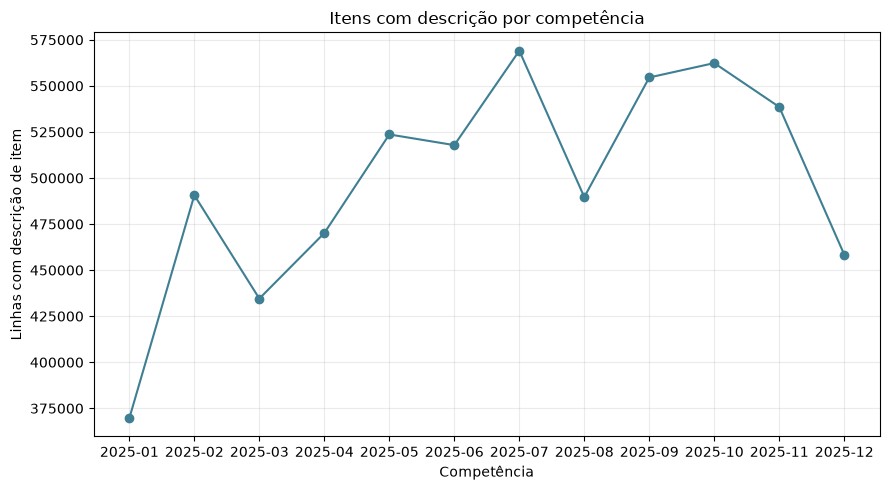

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(monthly_volume["competencia"], monthly_volume["linhas_com_descricao"], marker="o", color="#3f7f93")
ax.set_title("Itens com descrição por competência")
ax.set_xlabel("Competência")
ax.set_ylabel("Linhas com descrição de item")
ax.grid(alpha=0.25)
fig.tight_layout()


## Descrições mais frequentes

As frequências são calculadas diretamente sobre as ocorrências de `descricao_original` nos dados interim. Não há agregação ou normalização calculada sobre uma base agregada.


In [11]:
description_frequency = (
    df_items["descricao_original"].value_counts(dropna=True)
    .rename_axis("descricao_original").reset_index(name="frequencia")
)
top_descriptions = description_frequency.head(TOP_N)
top_descriptions


,descricao_original,frequencia
0,CADERNETA PACOM PF - NPB,27806
1,PERSONALIZACAO NOVO PASSAPORTE BRASILEIRO PACOM DPF 32 PAG.,24478
2,CENOURA,15387
3,MELANCIA,12891
4,GASOLINA COMUM,12018
5,BANANA PRATA,11905
6,CEBOLA,11444
7,TOMATE,11372
8,BETERRABA,11329
9,BATATA DOCE,11272


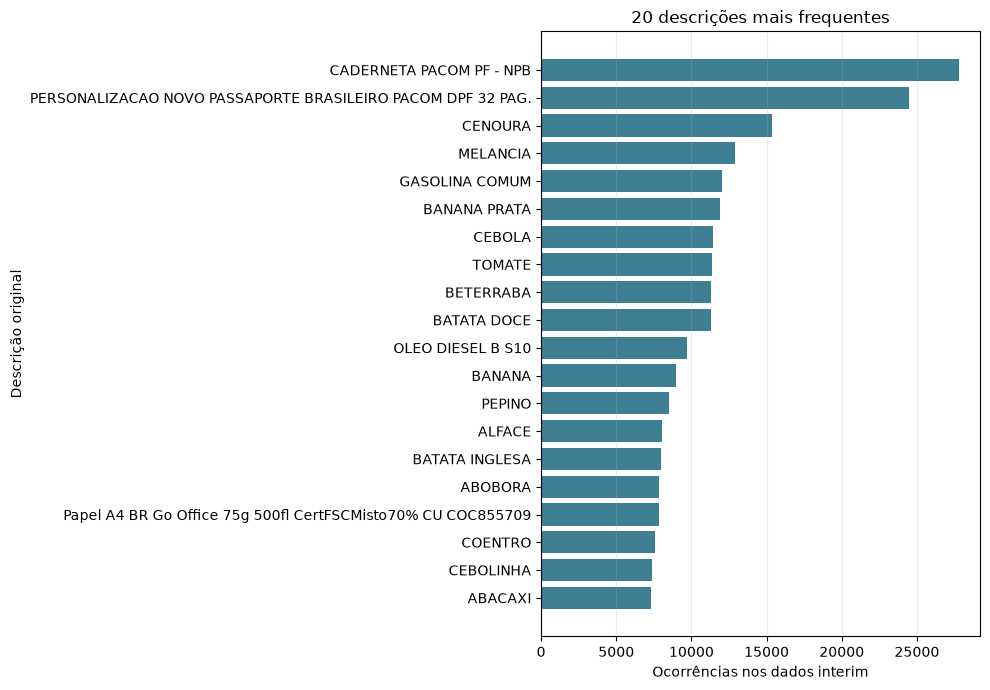

In [12]:
fig, ax = plt.subplots(figsize=(10, 7))
plot_data = top_descriptions.sort_values("frequencia")
ax.barh(plot_data["descricao_original"], plot_data["frequencia"], color="#3f7f93")
ax.set_title(f"{TOP_N} descrições mais frequentes")
ax.set_xlabel("Ocorrências nos dados interim")
ax.set_ylabel("Descrição original")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()


## Distribuição das frequências

A tabela e o gráfico mostram quantas descrições distintas aparecem em cada faixa de frequência.


In [13]:
frequency_summary = description_frequency["frequencia"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).to_frame("frequencia")
frequency_bands = pd.cut(
    description_frequency["frequencia"],
    bins=[0, 1, 2, 5, 10, 50, 100, 500, 1_000, float("inf")],
    labels=["1", "2", "3-5", "6-10", "11-50", "51-100", "101-500", "501-1000", ">1000"],
    right=True,
)
frequency_distribution = (
    frequency_bands.value_counts(sort=False).rename_axis("faixa_frequencia")
    .reset_index(name="descricoes_distintas")
)
frequency_distribution["proporcao_descricoes"] = frequency_distribution["descricoes_distintas"] / len(description_frequency)
display(frequency_summary)
frequency_distribution


,frequencia
count,1352762.0
mean,4.419967
std,63.591576
min,1.0
25%,1.0
50%,1.0
75%,2.0
90%,5.0
95%,10.0
99%,48.0


,faixa_frequencia,descricoes_distintas,proporcao_descricoes
0,1,861664,0.636966
1,2,211416,0.156285
2,3-5,155944,0.115278
3,6-10,59343,0.043868
4,11-50,51615,0.038155
5,51-100,7178,0.005306
6,101-500,4839,0.003577
7,501-1000,455,0.000336
8,>1000,308,0.000228


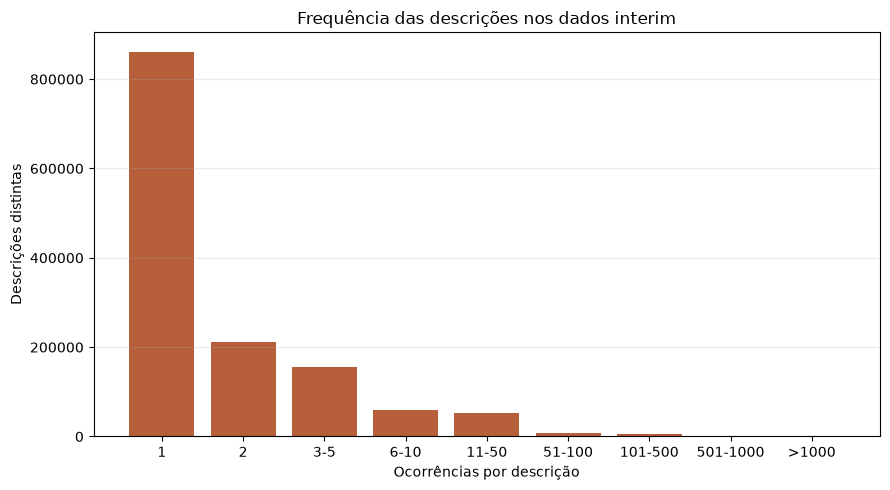

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(frequency_distribution["faixa_frequencia"].astype(str), frequency_distribution["descricoes_distintas"], color="#b65f3a")
ax.set_title("Frequência das descrições nos dados interim")
ax.set_xlabel("Ocorrências por descrição")
ax.set_ylabel("Descrições distintas")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()


## Características textuais e possíveis ruídos

As regras abaixo são heurísticas para orientar inspeção manual. Elas não removem itens nem definem rótulos de qualidade.


In [15]:
description_text = df_items["descricao_original"].dropna().astype("string").str.strip()
text_summary = pd.DataFrame({
    "metrica": ["ocorrências", "descrições distintas", "média de caracteres", "mediana de caracteres", "média de palavras", "com números (%)", "com caracteres especiais (%)"],
    "valor": [
        len(description_text), description_text.nunique(), description_text.str.len().mean(), description_text.str.len().median(),
        description_text.str.split().str.len().mean(),
        100 * description_text.str.contains(r"\d", regex=True, na=False).mean(),
        100 * description_text.str.contains(r"[^\w\s]", regex=True, na=False).mean(),
    ],
})
display(text_summary)

noise_candidates = df_items[["descricao_original", "competencia"]].drop_duplicates("descricao_original").copy()
noise_candidates["motivos_ruido"] = noise_candidates["descricao_original"].map(noise_reasons)
noise_examples = (
    noise_candidates[noise_candidates["motivos_ruido"].map(bool)]
    .merge(description_frequency, on="descricao_original", how="left")
    .assign(motivos_ruido=lambda frame: frame["motivos_ruido"].map(", ".join))
    .sort_values("frequencia", ascending=False)
    [["descricao_original", "frequencia", "motivos_ruido"]]
    .head(30)
)
noise_examples


,metrica,valor
0,ocorrências,5.979164e+06
1,descrições distintas,1.352762e+06
2,média de caracteres,3.482435e+01
3,mediana de caracteres,3.100000e+01
4,média de palavras,5.699421e+00
5,com números (%),6.076676e+01
6,com caracteres especiais (%),5.113429e+01


,descricao_original,frequencia,motivos_ruido
856,Papel A4 BR Go Office 75g 500fl CertFSCMisto70% CU COC855709,7814,muitos_digitos
653,HP CARTUCHO DE TONER PRETO 23.000 PAGINAS,3346,muitos_digitos
138137,PAPEL A4 75G 500FLS AUTOPAPER FSC CREDITO MISTO CERTIFICADO CU-COC-816590,3115,muitos_digitos
298,"ONU 1075,GAS LIQUEFEITO PETROLEO (GRANEL),2.1",2428,muitos_digitos
2618,Bloco Adesivo Go Office 75x100mm Azul Pastel,2142,muitos_digitos
2619,Bloco Adesivo Go Office 75x100mm Laranja Fluor,2064,muitos_digitos
2629,Fita Adesiva 3M 18mmX50m Durex Transparente,2051,muitos_digitos
2621,Bloco Adesivo Go Office 75x100mm Verde Pastel,1968,muitos_digitos
42,"ONU 1075 GAS(ES) DE PETROLEO, LIQUEFEITO(S), 2.1, GPL/GLP GRANEL",1923,muitos_digitos
2620,Bloco Adesivo Go Office 75x100mm Rosa Pastel,1901,muitos_digitos


## Principais NCMs

A associação entre código NCM e descrição do tipo de produto é lida da mesma base interim e agregada pelo número de ocorrências de item.


In [16]:
ncm_items = df_items.dropna(subset=["codigo_ncm"]).copy()
ncm_group_columns = ["codigo_ncm"] + (["ncm_tipo"] if "ncm_tipo" in ncm_items.columns else [])
top_ncms = (
    ncm_items.groupby(ncm_group_columns, dropna=False)
    .agg(frequencia=("descricao_original", "size"), descricoes_distintas=("descricao_original", "nunique"))
    .reset_index()
    .sort_values("frequencia", ascending=False)
    .head(TOP_N)
)
top_ncms


,codigo_ncm,ncm_tipo,frequencia,descricoes_distintas
3697,49019900,"Outros livros, brochuras e impressos semelhantes",444390,71757
7609,90189099,"Outros instrumentos e aparelhos para medicina, cirurgia, etc",293597,34967
7621,90211020,Artigos e aparelhos para fraturas,207370,37619
4781,7099990,"Outros produtos hortícolas, frescos ou refrigerados",75930,2646
7579,90183929,"Outras sondas, catéteres e cânulas",73679,14844
2806,38221990,NaN,70897,18607
7629,90213190,Outras próteses articulares,66909,6836
7343,87089990,Outras partes e acessórios para tratores e veículos automóveis,59736,28983
3715,49119900,Outros impressos,57343,1522
0,-1,NaN,53965,12672


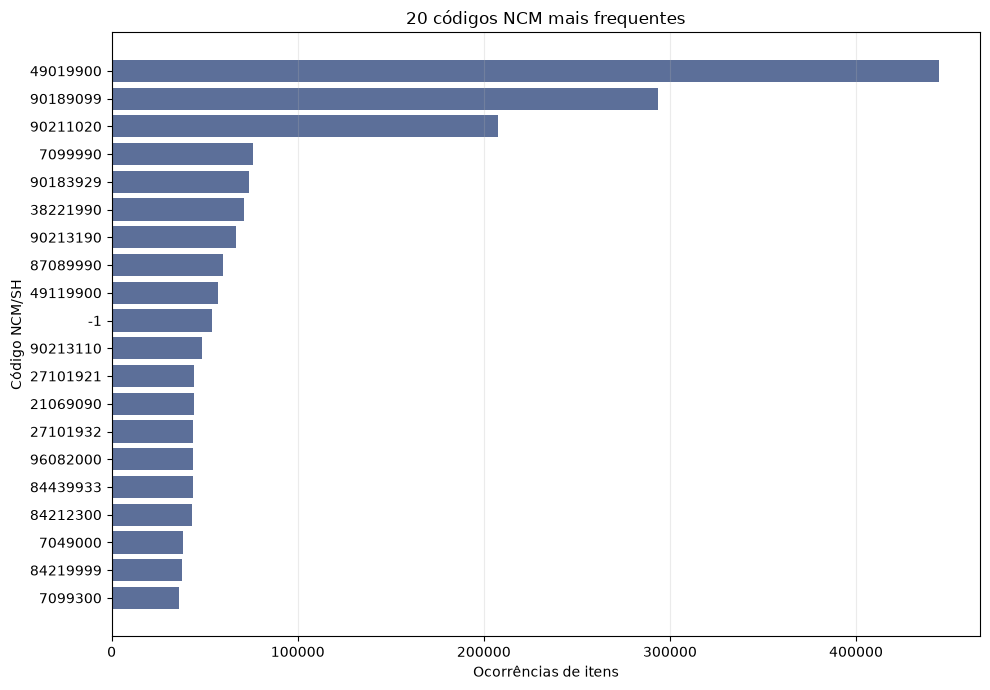

In [17]:
fig, ax = plt.subplots(figsize=(10, 7))
plot_data = top_ncms.sort_values("frequencia")
ax.barh(plot_data["codigo_ncm"].astype(str), plot_data["frequencia"], color="#5c6f99")
ax.set_title(f"{TOP_N} códigos NCM mais frequentes")
ax.set_xlabel("Ocorrências de itens")
ax.set_ylabel("C\u00f3digo NCM/SH")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()


## Variáveis fiscais

Os resumos cobrem somente itens com descrição preenchida. Uma variável que não exista nos arquivos selecionados é simplesmente omitida do resumo.


In [18]:
available_fiscal_columns = [column for column in FISCAL_COLUMN_TERMS if column in df_items.columns]
fiscal_summaries = pd.concat(
    [summarize_categorical_column(df_items, column) for column in available_fiscal_columns],
    ignore_index=True,
) if available_fiscal_columns else pd.DataFrame()
display(fiscal_summaries)

for column in available_fiscal_columns:
    display(top_categorical_values(df_items, column))


,coluna,total_itens,valores_ausentes,proporcao_ausente,valores_distintos,valor_mais_frequente
0,Série,5979164,0,0.000000e+00,489,1
1,Natureza da operação,5979164,5,8.362373e-07,24748,VENDA
2,Razão social emitente,5979164,0,0.000000e+00,91458,BRS SUPRIMENTOS CORPORATIVOS S/A
3,Consumidor final,5979164,0,0.000000e+00,2,1 - CONSUMIDOR FINAL
4,Presença do comprador,5979164,0,0.000000e+00,6,"9 - OPERAÇÃO NÃO PRESENCIAL, OUTROS"


,coluna,valor,total_itens,proporcao
0,Série,1,3978946,0.665469
1,Série,2,459357,0.076826
2,Série,4,324833,0.054327
3,Série,0,273778,0.045789
4,Série,890,241875,0.040453
5,Série,3,230276,0.038513
6,Série,5,92145,0.015411
7,Série,891,39397,0.006589
8,Série,100,38681,0.006469
9,Série,7,30301,0.005068


,coluna,valor,total_itens,proporcao
0,Natureza da operação,VENDA,294003,0.049171
1,Natureza da operação,Outra saida merc. prest. serv. nao especificado,266185,0.044519
2,Natureza da operação,Venda,223005,0.037297
3,Natureza da operação,VENDA DE MERCADORIA,220552,0.036887
4,Natureza da operação,RETORNO SIMBOLICO DE MERCADORIA DEPOSITADA EM DEPOSITO FECHA,155351,0.025982
5,Natureza da operação,VENDA DE MERCADORIA ADQUIRIDA OU RECEBIDA DE TERCEIROS,132843,0.022218
6,Natureza da operação,Venda de mercadoria adquirida ou recebida de terceiros,119713,0.020022
7,Natureza da operação,Venda de mercadoria,95443,0.015963
8,Natureza da operação,OUTRA SAIDA DE MERC. OU PREST.SERV. NAO ESPECIFICADO,89208,0.01492
9,Natureza da operação,SIMPLES REMESSA,81741,0.013671


,coluna,valor,total_itens,proporcao
0,Razão social emitente,BRS SUPRIMENTOS CORPORATIVOS S/A,260917,0.043638
1,Razão social emitente,EMPRES BRASILEIRA DE CORREIOS E TELEGRAFOS,159330,0.026648
2,Razão social emitente,ENDOLOG LOGISTICA E ARMAZENS LTDA,131460,0.021986
3,Razão social emitente,AUTOPEL AUTOMACAO COMERCIAL E INFORMATICA LTDA.,102570,0.017155
4,Razão social emitente,TRAUMINAS DIST MAT CIRURG HOSP LTDA,76508,0.012796
5,Razão social emitente,CASA DA MOEDA DO BRASIL,54541,0.009122
6,Razão social emitente,REFISERVI REFEICOES INDUSTRIAIS LTDA,48697,0.008144
7,Razão social emitente,BIO 2 IMP. E COM DE MAT. MED. HOSP. LTDA,40400,0.006757
8,Razão social emitente,EDITORA MODERNA LTDA.,40048,0.006698
9,Razão social emitente,EDITORA FTD S.A.,33807,0.005654


,coluna,valor,total_itens,proporcao
0,Consumidor final,1 - CONSUMIDOR FINAL,5178426,0.866079
1,Consumidor final,0 - NORMAL,800738,0.133921


,coluna,valor,total_itens,proporcao
0,Presença do comprador,"9 - OPERAÇÃO NÃO PRESENCIAL, OUTROS",2163220,0.361793
1,Presença do comprador,0 - NÃO SE APLICA,1850535,0.309497
2,Presença do comprador,1 - OPERAÇÃO PRESENCIAL,1684625,0.281749
3,Presença do comprador,"2 - OPERAÇÃO NÃO PRESENCIAL, PELA INTERNET",151914,0.025407
4,Presença do comprador,"3 - OPERAÇÃO NÃO PRESENCIAL, TELEATENDIMENTO",118610,0.019837
5,Presença do comprador,5 - NÃO INFORMADO,10260,0.001716


## Leituras para a metodologia

- As frequências representam ocorrências observadas diretamente nos arquivos interim selecionados.
- Linhas sem descrição foram excluídas das análises por item; a cobertura dessas linhas permanece visível na seção mensal.
- As heurísticas textuais são exemplos para inspeção, sem exclusões automáticas.
- Os NCMs ajudam a caracterizar a base e podem apoiar a interpretação, mas não são tratados aqui como rótulos finais.
- Os resumos dependem das competências presentes em `data/interim/items-notas-fiscais/` e do valor de `MONTHS`.
